# Defining the Game: Tic-Tac-Toe

## The Search Problem

A general search problem is defined in the following way:

* **Initial State:** Empty $3 \times 3$ board. It is the move for $x$.
* **Actions:** Place your symbol on any empty square.
* **Transition function:** You symbol is placed on the board according to the action. The opponent
    places her symbol. From our viewpoint this makes the environment non-deterministic.
* **Goal state:** A win (three symbols in a row, column or diagonal). 
* **Path cost:** number of moves.
  
Since Tic-tac-toe is a game, we will use the more specializes components (see Chapter 5):
* `Actions(s)` Legal moves in state s.
* `Result(s, a)` Transition model.
* `Terminal(s)` Test for terminal states.
* `Utility(s)` Utility for player Max for terminal states.

**Notes:**

* To define the goal state we will use a test for a **terminal state** (game is over) and a **utility function** (win or loose). 
* We will use DFS which is not optimal. So will probably not find the solution with the lowest path cost, i.e., win with the smallest number of moves. Therefore, we drop the path cost all together.

## Problem Size

### State Space Estimates

Each state is a possible board. Each of the 9 squares can have 3 values (empty, x and o), but some boards are impossible (where a player has several sequences of 3).The number of states in the state space graph is less than $3^9$.

In [21]:
3**9

19683

A tighter bound for the search space size would be looking at all the ways we can choose $i = 1,2,3,...,9$ places from the board given by ${9 \choose i}$. Now we need to find all ways how we can choose half the symbols for player o which is given by ${i \choose \lfloor \frac{i}{2} \rfloor}$. 
Put together we get $\sum_{i=1}^9{{9 \choose i}{i \choose \lfloor \frac{i}{2} \rfloor}}$.

In [22]:
import math

print("level\tboards")
sum = 0

for i in range(1,9):
    sum += math.comb(9, i) * math.comb(i, math.floor(i/2))
    print(i, "\t", math.comb(9, i) , " x ", math.comb(i, math.floor(i/2)) , " = ",  math.comb(9, i) * math.comb(i, math.floor(i/2)))

sum

level	boards
1 	 9  x  1  =  9
2 	 36  x  2  =  72
3 	 84  x  3  =  252
4 	 126  x  6  =  756
5 	 126  x  10  =  1260
6 	 84  x  20  =  1680
7 	 36  x  35  =  1260
8 	 9  x  70  =  630


5919

This is an upper bound since it contains some infeasible boards where both players have 3 in a row.

### Space and Time Complexity Using the Search Tree Estimates

For solving the problem, we use the search tree which can be significantly larger than the state space.
A search tree is a subgraph with all **cycles removed.** The standard implementation of DFS **cannot remove redundant paths** (i.e., getting to the same board by plcing symbols in a different order). Therefore, a state can be represented by several nodes in different branches! We observe the following:

* The complete search tree has a maximal depth $m=9$
* The max branching factor $b=9$ (for first move).

DFS has

* a space complexity of $O(bm)$ (current path plus frontier) and 
* a time complecity of $O(b^m)$ (number of expanded nodes).

In [23]:
# Space Complexity O(bm):
9*9

81

In [24]:
# Time Complexity O(b^m): 
9**9

387420489

The branching factor decreases after each move. The first level has a branching factor of 9, the second a branching factor of 8, etc. The total number of nodes is:

| <div style="width:100px">Level</div>      |  <div style="width:200px"># of nodes</div>   |
| :------------- | :---------------- |
| root       | $1$ |
| level 1    | $9 = 9!/8!$ |
| level 2    | $9 \times 8 = 9!/7!$ |
| level 2    | $9 \times 8 \times 7 = 9!/6!$ |
| ...        |  ... |
| level 9    | $9 \times 8 \times \dots \times 2 \times 1 = 9!$ |

The total number of game tree nodes is less (some games end early) than the sum of the nodes above. The upper bound for the number of nodes is

$\sum_{i = 0}^9 \frac{9!}{i!}$

In [25]:
sum = 1
partial_fac = 1
print("level\t# nodes")
print("root\t 1")

for i in range(9, 0, -1):
    partial_fac *= i
    sum += partial_fac 
    print(10-i, "\t", partial_fac)
    
sum

level	# nodes
root	 1
1 	 9
2 	 72
3 	 504
4 	 3024
5 	 15120
6 	 60480
7 	 181440
8 	 362880
9 	 362880


986410

Since some sequences are cut short because of a win, we expect fewer nodes in the game complete tree.

**Redundant paths:** The tree size estimation contains redundant paths.

**Cycles:** Tic-tac-toe does not have cycles (you cannot remove a played symbol).


__Note:__ This size makes tic-tac-toe a very small problem that can be easily solved by tree search. Most games and real problems are too large and cannot be solved this way. For example, chess has an estimated state space size of $>10^{30}$. 
We will learn several methods that address this problem later.

In [26]:
# [Bài 1] Kiểm chứng ước lượng bằng cách liệt kê toàn bộ cây trò chơi (có nhớ kết quả từng trạng thái).
# Import tại đây vì ô này nằm trước phần Implementation (nơi notebook gốc import tictactoe).
from functools import lru_cache
from tictactoe import empty_board, actions, result, terminal, check_board

@lru_cache(maxsize=None)
def count_games(key):
    """Từ trạng thái `key` (chuỗi 9 ký tự): số ván kết thúc bằng x thắng, o thắng, hòa."""
    state = list(key)
    if terminal(state):
        winner = check_board(state)
        return (winner == 'x', winner == 'o', winner == 'd')
    player = 'x' if state.count('x') == state.count('o') else 'o'
    totals = [0, 0, 0]
    for a in actions(state):
        for k, v in enumerate(count_games(''.join(result(state, player, a)))):
            totals[k] += v
    return tuple(totals)

x_games, o_games, d_games = count_games(' ' * 9)
reachable_states = count_games.cache_info().currsize
print('Số trạng thái đạt được (kể cả bàn trống):', reachable_states)
print('Số ván khác nhau:', x_games + o_games + d_games, f'(x thắng {x_games}, o thắng {o_games}, hòa {d_games})')

Số trạng thái đạt được (kể cả bàn trống): 5478
Số ván khác nhau: 255168 (x thắng 131184, o thắng 77904, hòa 46080)


**[Bài 1] Nhận xét: kiểm chứng ước lượng bằng cách liệt kê.** Ô trên duyệt toàn bộ cây trò chơi (có nhớ kết quả của
từng trạng thái nên chạy rất nhanh):
- Có **5.478 trạng thái** đạt được (kể cả bàn trống), nhỏ hơn cả hai cận trên ở trên: $3^9 = 19.683$ và cận theo tổ hợp.
  Lưu ý ô gốc lặp `range(1, 9)` nên chỉ cộng $i = 1..8$ và ra 5.919; cộng đủ $i = 9$ (thêm 126) và bàn trống thì cận là 6.046.
  Số thật nhỏ hơn vì cận trên còn đếm cả những bàn không thể xảy ra (cả hai cùng có 3 quân thẳng hàng, hoặc vẫn đi tiếp sau khi đã có người thắng).
- Có **255.168 ván** khác nhau (x thắng 131.184, o thắng 77.904, hòa 46.080), so với cận trên $9! = 362.880$ lá: nhiều ván
  kết thúc sớm khi có người thắng nên cây thật nhỏ hơn cận.
- Đây là kích thước rất nhỏ, nên Tic-Tac-Toe giải được bằng tìm kiếm đầy đủ (các Bài 2–4).

## Implementation

We need to implement the following functions:

* `Actions(s)` Legal moves in state s.
* `Result(s, a)` Transition model.
* `Terminal(s)` Test for terminal states.
* `Utility(s)` Utility for player Max for terminal states.

The state (a board position) will be implemented as a vector (in Python this is a list) of length 9. The values are `' ', 'x', 'o'`. The actions are just the index in the list (0, 1, 2, ..., 8).


The implementation of these and some other helper functions can be found in [tictactoe.py](tictactoe.py)
and be imported from that file

In [27]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [28]:
from tictactoe import empty_board, actions, result, terminal, utility
from tictactoe import show_board, show_board_text

### [Bài 1] Mô tả cách cài đặt trong `tictactoe.py`

**Biểu diễn trạng thái:** bàn cờ là một list 9 phần tử, mỗi phần tử là `' '` (trống), `'x'` hoặc `'o'`.
Chỉ số ô đánh từ trái sang phải, trên xuống dưới:

```
0 | 1 | 2
---------
3 | 4 | 5
---------
6 | 7 | 8
```

| Hàm | Vai trò |
| :--- | :--- |
| `empty_board()` | Trạng thái ban đầu: list 9 ô trống. `x` luôn đi trước. |
| `actions(board)` | Danh sách chỉ số các ô còn trống (nước đi hợp lệ), theo thứ tự tăng dần. |
| `result(state, player, action)` | Mô hình chuyển trạng thái: **sao chép** bàn rồi đặt quân `player` vào ô `action`; ô đã có quân thì báo lỗi. Không sửa bàn cũ. |
| `check_board(state)` | Kiểm tra 3 hàng, 3 cột, 2 đường chéo: trả `'x'` hoặc `'o'` nếu có người thắng, `'d'` nếu bàn đầy mà hòa, `'n'` nếu ván chưa kết thúc. |
| `terminal(state)` | Ván đã kết thúc chưa: `check_board(state) != 'n'`. |
| `utility(state, player)` | Theo góc nhìn `player`: **+1** thắng, **0** hòa, **−1** thua, `None` nếu ván chưa kết thúc. |
| `other(player)` | Đổi lượt: `'x'` ↔ `'o'`. |
| `show_board_text`, `show_board` | Hiển thị bàn dạng chữ (mảng 3×3) và dạng hình. |
| `random_player`, `play` | Agent chọn ngẫu nhiên một ô trống; môi trường cho hai agent đấu N ván (x đi trước), trả số ván x thắng / o thắng / hòa. |

## Examples

In [29]:
board = empty_board()
board[0] = 'x'; board[3] = 'x'; board[6] = 'x'; board[1] = 'o'; board[4] = 'o'  
display(board)

['x', 'o', ' ', 'x', 'o', ' ', 'x', ' ', ' ']

In [30]:
show_board_text(board)

[['x' 'o' ' ']
 ['x' 'o' ' ']
 ['x' ' ' ' ']]


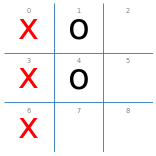

In [31]:
show_board(board)

In [32]:
actions(board)

[2, 5, 7, 8]

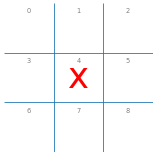

In [33]:
board2 = empty_board()
board2 = result(board2, 'x', 4)
show_board(board2)

In [34]:
print(terminal(board))
print(terminal(board2))

True
False


In [35]:
# [Bài 1] Chạy thêm check_board, utility và kiểm tra nước đi không hợp lệ.
from tictactoe import check_board, other

print('board :', check_board(board), '| utility theo x:', utility(board, 'x'), '| theo o:', utility(board, 'o'))
print('board2:', check_board(board2), '| utility theo x:', utility(board2, 'x'))

full = list('xoxxoooxx')   # bàn đầy, không ai có 3 quân thẳng hàng
show_board_text(full)
print('bàn đầy:', check_board(full), '| terminal:', terminal(full), '| utility theo x:', utility(full, 'x'))

try:
    result(board, 'o', 0)          # ô 0 đã có quân x
except Exception as e:
    print('Nước đi không hợp lệ bị từ chối:', e)

board : x | utility theo x: 1 | theo o: -1
board2: n | utility theo x: None
[['x' 'o' 'x']
 ['x' 'o' 'o']
 ['o' 'x' 'x']]
bàn đầy: d | terminal: True | utility theo x: 0
Nước đi không hợp lệ bị từ chối: Illegal action 0 by player o!


**[Bài 1] Nhận xét các ví dụ.**
- `board` có x ở 0, 3, 6 (thẳng cột trái) nên `check_board` trả `'x'`, `terminal` là `True`, utility là **+1** theo x và **−1** theo o.
  `actions(board)` trả `[2, 5, 7, 8]`, đúng các ô còn trống.
- `board2` chỉ có một quân x ở ô 4 nên ván chưa xong: `check_board` trả `'n'`, `terminal` là `False`, utility là `None`.
- Bàn đầy không ai thắng: `check_board` trả `'d'`, utility là **0**.
- Đặt quân vào ô đã có quân bị `result` từ chối, nên agent không thể đi nước sai.

## Experiments


### Baseline: Randomized Player

A completely randomized player agent can be used as a weak baseline. A simple random agent and a the game environment
are implemented in [tictactoe.py](tictactoe.py) as `random_player()` and `play()`, respectively.

In [36]:
from tictactoe import random_player, play 

### Random vs. Random

Let a random player play another random player for 100 games and look at the number of wins.

In [37]:
%time display(play(random_player, random_player, N = 100))

{'x': 56, 'o': 28, 'd': 16}

CPU times: total: 46.9 ms
Wall time: 62.6 ms


_Note:_ It looks like the first player (x) has an advantage!

### [Bài 1] Random đấu Random 1000 ván

Ô gốc phía trên chỉ chạy 100 ván và **không cố định seed**, nên mỗi lần chạy ra kết quả khác nhau. Theo yêu cầu,
nhóm chạy thêm **1000 ván với seed 42** để số liệu tái lập được, và so với **xác suất chính xác** khi cả hai chọn ngẫu nhiên
đều (tính bằng cách duyệt toàn bộ cây trò chơi, mỗi nhánh có xác suất bằng nhau).

In [39]:
# [Bài 1] Random đấu Random 1000 ván (seed 42), so với xác suất chính xác khi cả hai chơi ngẫu nhiên đều.
import time
import numpy as np
import pandas as pd

@lru_cache(maxsize=None)
def random_outcome(key):
    """Xác suất (x thắng, o thắng, hòa) khi từ trạng thái `key` hai bên chọn ngẫu nhiên đều ô trống."""
    state = list(key)
    if terminal(state):
        winner = check_board(state)
        return (float(winner == 'x'), float(winner == 'o'), float(winner == 'd'))
    player = 'x' if state.count('x') == state.count('o') else 'o'
    moves = actions(state)
    totals = [0.0, 0.0, 0.0]      # không dùng sum(): ô gốc phía trên đã gán đè biến tên `sum`
    for a in moves:
        for k, p in enumerate(random_outcome(''.join(result(state, player, a)))):
            totals[k] += p / len(moves)
    return tuple(totals)

exact = random_outcome(' ' * 9)

np.random.seed(42)
start = time.perf_counter()
res = play(random_player, random_player, N=1000)
elapsed = time.perf_counter() - start

random_1000 = pd.DataFrame({
    'kết quả': ['x thắng (đi trước)', 'o thắng', 'hòa'],
    'số ván / 1000': [res['x'], res['o'], res['d']],
    'tỷ lệ quan sát': [res['x'] / 1000, res['o'] / 1000, res['d'] / 1000],
    'xác suất chính xác': [round(p, 4) for p in exact],
})
print(f'Thời gian 1000 ván: {elapsed:.2f} s')
random_1000

Thời gian 1000 ván: 0.27 s


,kết quả,số ván / 1000,tỷ lệ quan sát,xác suất chính xác
0,x thắng (đi trước),590,0.590,0.5849
1,o thắng,284,0.284,0.2881
2,hòa,126,0.126,0.1270


**[Bài 1] Nhận xét: lợi thế của người đi trước.**
- Kết quả 1000 ván: **x thắng 590 (59,0%), o thắng 284 (28,4%), hòa 126 (12,6%)**. Cả ba tỷ lệ đều sát xác suất chính xác
  58,5% / 28,8% / 12,7% (lệch dưới 0,6 điểm phần trăm, trong khi độ lệch chuẩn của tỷ lệ với 1000 ván khoảng 1,6 điểm).
- **Người đi trước (x) thắng gần gấp đôi người đi sau.** Lý do: x đi 5 trong 9 nước và có thể hoàn thành 3 quân thẳng hàng
  sớm nhất ở nước thứ 5 của ván, còn o sớm nhất ở nước thứ 6. Khi hai bên chơi ngẫu nhiên và không ai chặn, ai có nhiều quân
  hơn và tới đích sớm hơn sẽ thắng nhiều hơn. Ngay cả khi đếm mọi ván có thể xảy ra (ô liệt kê ở trên), x cũng thắng 131.184 ván,
  nhiều hơn o (77.904 ván).
- Lợi thế này là do đối thủ chơi ngẫu nhiên. Nếu cả hai chơi tối ưu thì Tic-Tac-Toe luôn **hòa** (giá trị Minimax của bàn trống
  là 0, xem Bài 3).

In [40]:
# [Bài 1] Dòng "Random" cho bảng tổng hợp của nhóm: 100 ván, agent đi trước (x), seed 42, có thời gian mỗi nước.
def measured(agent, times):
    """Bọc agent để đo thời gian từng nước đi."""
    def wrapped(board, player='x'):
        start = time.perf_counter()
        move = agent(board, player)
        times.append(time.perf_counter() - start)
        return move
    return wrapped

np.random.seed(42)
times = []
res100 = play(measured(random_player, times), random_player, N=100)
pd.DataFrame([{'agent (đi trước)': 'Random', 'đối thủ': 'Random', 'số ván': 100,
               'thắng': res100['x'], 'hòa': res100['d'], 'thua': res100['o'],
               'TG TB/nước (ms)': round(1000 * float(np.mean(times)), 4)}])

,agent (đi trước),đối thủ,số ván,thắng,hòa,thua,TG TB/nước (ms)
0,Random,Random,100,58,17,25,0.0146


**[Bài 1] Nhận xét: số liệu cho bảng tổng hợp của nhóm.** Cùng điều kiện với các bài khác (100 ván, agent đi trước, seed 42),
Random thắng **58**, hòa **17**, thua **25**, khớp với lợi thế đi trước ở trên. Mỗi nước mất chưa tới 0,1 ms vì agent
không tìm kiếm gì; đây là mốc yếu nhất để so với các agent ở Bài 2–6.